In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# 1. Load Dataset
df = pd.read_csv("../Dataset/Churn_Modelling.csv")

# 2. Drop irrelevant metadata
df_clean = df.drop(columns=["RowNumber", "CustomerId", "Surname"])

# 3. Define Features (X) and Target (y)
X = df_clean.drop(columns=["Exited"])
y = df_clean["Exited"]

# 4. Perform 70/30 Stratified Train-Test Split FIRST (Prevents Data Leakage)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# 5. Define Feature Groups
num_cols = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "EstimatedSalary"]
cat_cols = ["Geography", "Gender"]

# 6. Build Preprocessing Pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols)
    ],
    remainder="passthrough" # Keeps binary columns like HasCrCard, IsActiveMember
)

# Fit preprocessor ONLY on training data, then transform both sets
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

print("Data successfully loaded, split, and preprocessed!")
print(f"Training shape: {X_train_prep.shape}, Testing shape: {X_test_prep.shape}")

Data successfully loaded, split, and preprocessed!
Training shape: (7000, 11), Testing shape: (3000, 11)


In [2]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

models = {
    "Baseline (Dummy)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "K-Nearest Neighbors": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "XGBoost": XGBClassifier(random_state=42, eval_metric="logloss")
}

results = []

for name, model in models.items():
    model.fit(X_train_prep, y_train)
    y_pred = model.predict(X_test_prep)
    
    y_proba = model.predict_proba(X_test_prep)[:, 1] if hasattr(model, "predict_proba") else y_pred
        
    results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "Precision": round(precision_score(y_test, y_pred, zero_division=0), 4),
        "Recall": round(recall_score(y_test, y_pred, zero_division=0), 4),
        "F1-Score": round(f1_score(y_test, y_pred, zero_division=0), 4),
        "ROC-AUC": round(roc_auc_score(y_test, y_proba), 4)
    })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

              Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
   Baseline (Dummy)    0.7963     0.0000  0.0000    0.0000   0.5000
Logistic Regression    0.8130     0.6316  0.1964    0.2996   0.7881
K-Nearest Neighbors    0.8447     0.6845  0.4403    0.5359   0.8069
      Decision Tree    0.7917     0.4888  0.4992    0.4939   0.6828
      Random Forest    0.8683     0.7842  0.4877    0.6014   0.8652
            XGBoost    0.8637     0.7371  0.5139    0.6056   0.8487


Best Random Forest Parameters: {'max_depth': 15, 'min_samples_split': 5, 'n_estimators': 200}
Best XGBoost Parameters: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 100}

--- Tuned Random Forest Classification Report ---
              precision    recall  f1-score   support

           0       0.91      0.89      0.90      2389
           1       0.61      0.66      0.64       611

    accuracy                           0.85      3000
   macro avg       0.76      0.78      0.77      3000
weighted avg       0.85      0.85      0.85      3000


--- Tuned XGBoost Classification Report ---
              precision    recall  f1-score   support

           0       0.93      0.83      0.88      2389
           1       0.53      0.75      0.62       611

    accuracy                           0.81      3000
   macro avg       0.73      0.79      0.75      3000
weighted avg       0.85      0.81      0.82      3000



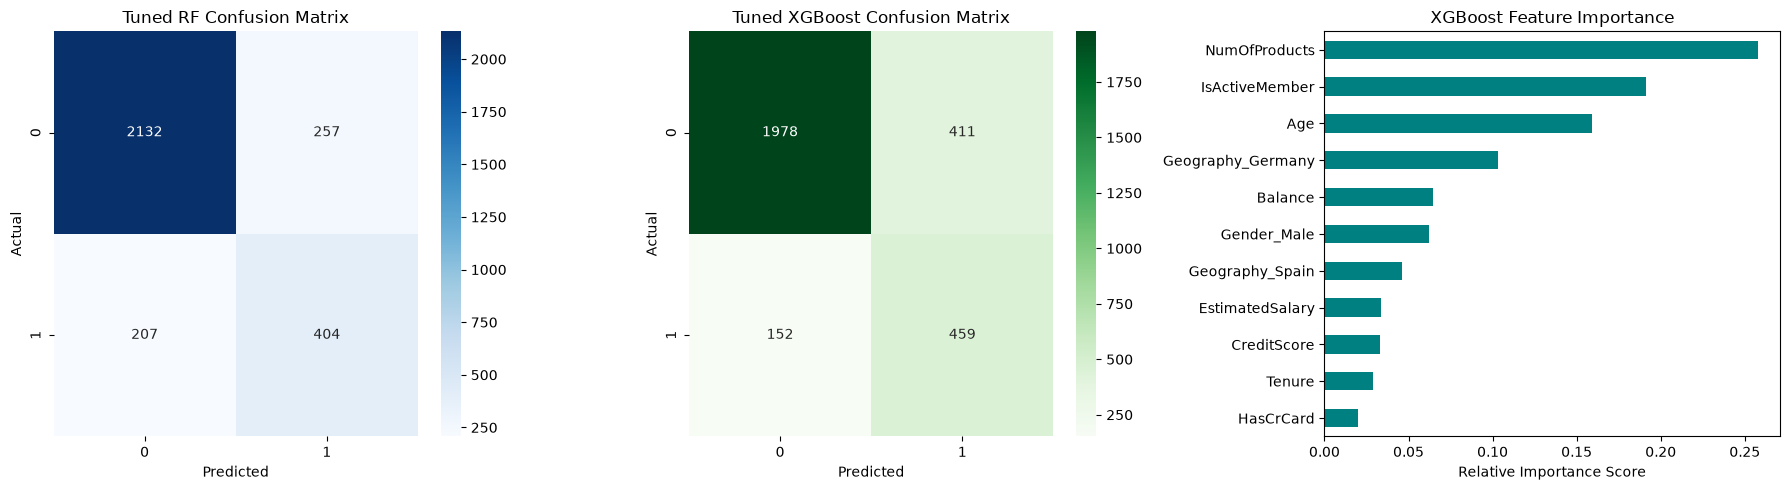

In [3]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns

from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc

# ---------------------------------------------------------
# 1. Class Imbalance Ratio for XGBoost (Negatives / Positives)
# ---------------------------------------------------------
ratio = (y_train == 0).sum() / (y_train == 1).sum()

# ---------------------------------------------------------
# 2. Hyperparameter Tuning for Random Forest
# ---------------------------------------------------------
rf_params = {
    'n_estimators': [100, 200],
    'max_depth': [6, 10, 15],
    'min_samples_split': [2, 5]
}

rf_grid = GridSearchCV(
    RandomForestClassifier(class_weight='balanced', random_state=42),
    rf_params,
    cv=5,
    scoring='f1',
    n_jobs=-1
)
rf_grid.fit(X_train_prep, y_train)
best_rf = rf_grid.best_estimator_

# ---------------------------------------------------------
# 3. Hyperparameter Tuning for XGBoost
# ---------------------------------------------------------
xgb_params = {
    'n_estimators': [100, 200],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1]
}

xgb_grid = GridSearchCV(
    XGBClassifier(scale_pos_weight=ratio, random_state=42, eval_metric='logloss'),
    xgb_params,
    cv=5,
    scoring='f1',
    n_jobs=-1
)
xgb_grid.fit(X_train_prep, y_train)
best_xgb = xgb_grid.best_estimator_

print(f"Best Random Forest Parameters: {rf_grid.best_params_}")
print(f"Best XGBoost Parameters: {xgb_grid.best_params_}")

# ---------------------------------------------------------
# 4. Evaluate Tuned Models
# ---------------------------------------------------------
y_pred_rf = best_rf.predict(X_test_prep)
y_pred_xgb = best_xgb.predict(X_test_prep)

print("\n--- Tuned Random Forest Classification Report ---")
print(classification_report(y_test, y_pred_rf))

print("\n--- Tuned XGBoost Classification Report ---")
print(classification_report(y_test, y_pred_xgb))

# ---------------------------------------------------------
# 5. Visualizations: Confusion Matrices & Feature Importance
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Confusion Matrix: Tuned Random Forest
sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title("Tuned RF Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

# Confusion Matrix: Tuned XGBoost
sns.heatmap(confusion_matrix(y_test, y_pred_xgb), annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title("Tuned XGBoost Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

# Feature Importance from Tuned XGBoost
# Reconstruct feature names post One-Hot Encoding
encoded_cat_names = list(preprocessor.named_transformers_['cat'].get_feature_names_out(cat_cols))
all_feature_names = num_cols + encoded_cat_names + ["HasCrCard", "IsActiveMember"]

importances = best_xgb.feature_importances_
feat_imp = pd.Series(importances, index=all_feature_names).sort_values(ascending=True)

feat_imp.plot(kind='barh', ax=axes[2], color='teal')
axes[2].set_title("XGBoost Feature Importance")
axes[2].set_xlabel("Relative Importance Score")

plt.tight_layout()
plt.savefig("../Report/Model_Evaluation_Plots.png", dpi=300)
plt.show()